# Netflix Content Type Analysis

---



## Project Overview

This notebook analyzes the distribution of Netflix content based on content type, focusing on Movies and TV Shows.

The analysis aims to examine the composition of Netflix's content catalog by comparing the number and proportion of Movies and TV Shows.

### Objectives

1. Analyze the distribution of Movies and TV Shows.
2. Calculate the total number of titles for each content type.
3. Compare the proportions of Movies and TV Shows.
4. Identify key findings from the content type distribution.

### Dataset

The analysis uses the cleaned Netflix dataset generated in the previous notebook.

### Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Expected Deliverables

- Content type distribution summary.
- Comparative visualizations of Movies and TV Shows.
- Content proportion analysis.
- Key findings and summary report.

---

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid')

## Data Loading

The cleaned Netflix dataset is loaded from the output of the previous data cleaning process.

In [2]:
# Define dataset path
file_path = Path("../Dataset/Cleaned_Netflix_Data.csv")

# Load cleaned dataset
df = pd.read_csv(file_path, parse_dates=['date_added'])

print("Dataset loaded successfully!")
print(f"Total Records: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

Dataset loaded successfully!
Total Records: 8,786
Total Columns: 10


### Preview Dataset

In [3]:
display(df.head())

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Content Type Distribution Analysis

This section examines the distribution of Movies and TV Shows in the Netflix catalog.

The analysis focuses on calculating the number and percentage of each content type to understand the overall composition of the catalog.

### Content Type Count and Percentage

This section calculates the total number of Movies and TV Shows and their respective percentages of the overall Netflix catalog.

In [4]:
# Calculate content type distribution
content_type_summary = (
    df['type']
    .value_counts()
    .reset_index()
)

content_type_summary.columns = ['Content Type', 'Count']

# Calculate percentage
content_type_summary['Percentage'] = (
    content_type_summary['Count'] / len(df) * 100
)

# Round percentage values
content_type_summary['Percentage'] = (
    content_type_summary['Percentage'].round(2)
)

display(content_type_summary)

,Content Type,Count,Percentage
0,Movie,6123,69.69
1,TV Show,2663,30.31


### Content Type Visualization

Bar and pie charts are used to visualize the distribution of Movies and TV Shows.

The bar chart compares the total number of titles, while the pie chart illustrates the proportion of each content type in the Netflix catalog.

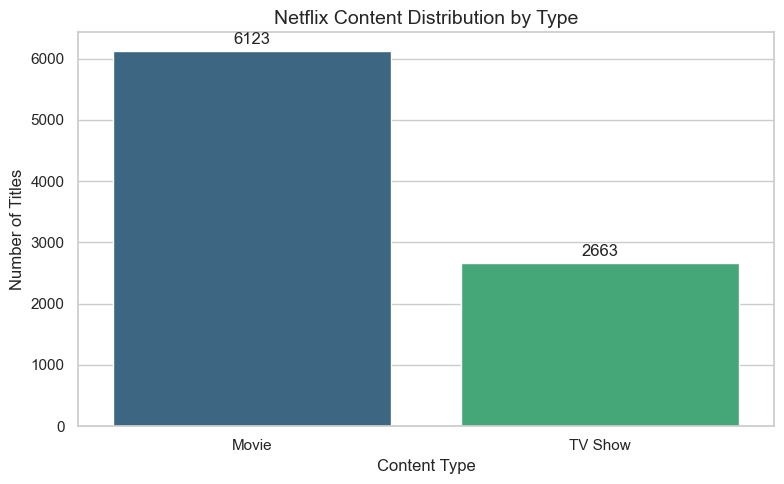

In [5]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=content_type_summary,
    x='Content Type',
    y='Count',
    hue='Content Type',
    palette='viridis',
    legend=False
)

plt.title('Netflix Content Distribution by Type', fontsize=14)
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

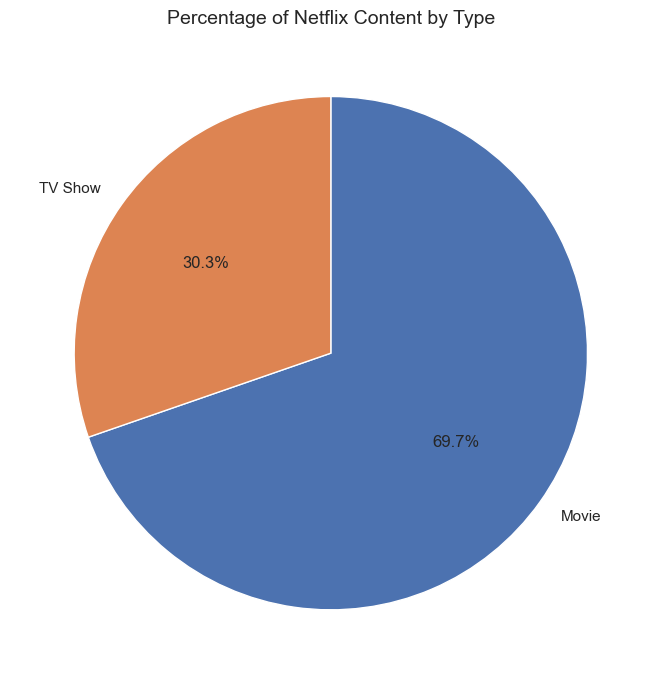

In [6]:
# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    content_type_summary['Count'],
    labels=content_type_summary['Content Type'],
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False
)

plt.title('Percentage of Netflix Content by Type', fontsize=14)
plt.tight_layout()
plt.show()

## Key Findings and Business Insights

### Key Findings
The analysis reveals the following findings:

1. **Movie Dominance:** Movies account for 6,123 titles, representing 69.69% of the total Netflix catalog.
2. **TV Show Representation:** TV Shows account for 2,663 titles, representing 30.31% of the catalog.
3. **Content Distribution:** The number of Movies is approximately 2.3 times higher than the number of TV Shows.

### Business Insights

The Netflix catalog in this dataset is predominantly composed of Movies, with film titles representing a substantially larger share than TV Shows.

This distribution provides an overview of the catalog's content composition and establishes a basis for further analysis of content characteristics across different categories.

However, catalog representation should not be interpreted as audience preference or viewing performance, as the dataset does not contain viewership or engagement metrics.